He so goc a: 31.714285714285715
He so chan b: -78.0952380952383
Phuong trinh: y = 31.71x + -78.10
Gia nha du doan: 2300.48 trieu VND


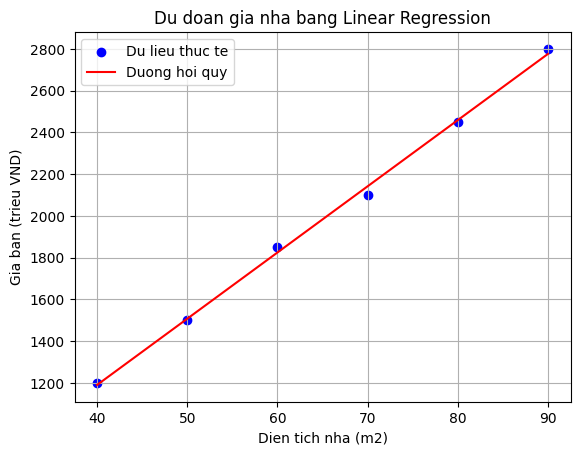

In [3]:

#BAI1
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


X = np.array([40, 50, 60, 70, 80, 90]).reshape(-1, 1)


y = np.array([1200, 1500, 1850, 2100, 2450, 2800])

model = LinearRegression()


model.fit(X, y)

a = model.coef_[0]
b = model.intercept_

print("He so goc a:", a)
print("He so chan b:", b)
print(f"Phuong trinh: y = {a:.2f}x + {b:.2f}")


dien_tich_moi = np.array([[75]])
gia_du_doan = model.predict(dien_tich_moi)

print("Gia nha du doan:", round(gia_du_doan[0], 2), "trieu VND")


plt.scatter(X, y, color="blue", label="Du lieu thuc te")

x_line = np.linspace(40, 90, 100).reshape(-1, 1)
y_line = model.predict(x_line)

plt.plot(x_line, y_line, color="red", label="Duong hoi quy")
plt.xlabel("Dien tich nha (m2)")
plt.ylabel("Gia ban (trieu VND)")
plt.title("Du doan gia nha bang Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

Do chinh xac: 0.84

Ma tran nham lan:
[[ 80  24]
 [ 16 130]]

10 mau dau tien trong tap test:
BMI=29.19, Nhan thuc te=1, Xac suat nhan 1=0.718, Nhan du doan=1
BMI=36.72, Nhan thuc te=1, Xac suat nhan 1=0.972, Nhan du doan=1
BMI=32.42, Nhan thuc te=1, Xac suat nhan 1=0.887, Nhan du doan=1
BMI=29.77, Nhan thuc te=1, Xac suat nhan 1=0.757, Nhan du doan=1
BMI=23.45, Nhan thuc te=0, Xac suat nhan 1=0.255, Nhan du doan=0
BMI=19.63, Nhan thuc te=0, Xac suat nhan 1=0.083, Nhan du doan=0
BMI=33.54, Nhan thuc te=1, Xac suat nhan 1=0.921, Nhan du doan=1
BMI=24.36, Nhan thuc te=0, Xac suat nhan 1=0.320, Nhan du doan=0
BMI=29.53, Nhan thuc te=1, Xac suat nhan 1=0.741, Nhan du doan=1
BMI=16.59, Nhan thuc te=0, Xac suat nhan 1=0.030, Nhan du doan=0


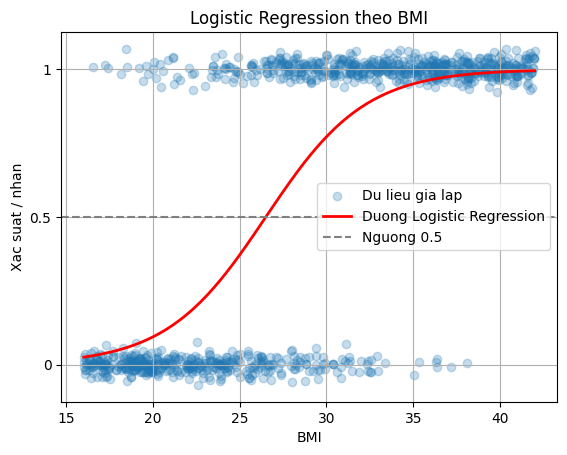

In [4]:

#Bai2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix


rng = np.random.default_rng(42)

n = 1000

BMI = rng.uniform(16, 42, n)


xac_suat = 1 / (1 + np.exp(-(BMI - 27) / 2.8))


Mac_benh = rng.binomial(1, xac_suat)


X = BMI.reshape(-1, 1)
y = Mac_benh


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


model = LogisticRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)


y_proba = model.predict_proba(X_test)[:, 1]


accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Do chinh xac:", round(accuracy, 4))
print("\nMa tran nham lan:")
print(cm)


print("\n10 mau dau tien trong tap test:")

for i in range(min(10, len(X_test))):
    print(
        f"BMI={X_test[i, 0]:.2f}, "
        f"Nhan thuc te={y_test[i]}, "
        f"Xac suat nhan 1={y_proba[i]:.3f}, "
        f"Nhan du doan={y_pred[i]}"
    )


BMI_grid = np.linspace(BMI.min(), BMI.max(), 300).reshape(-1, 1)


prob_grid = model.predict_proba(BMI_grid)[:, 1]

plt.scatter(
    BMI,
    Mac_benh + rng.normal(0, 0.025, n),
    alpha=0.25,
    label="Du lieu gia lap"
)

plt.plot(
    BMI_grid[:, 0],
    prob_grid,
    color="red",
    linewidth=2,
    label="Duong Logistic Regression"
)

plt.axhline(0.5, color="gray", linestyle="--", label="Nguong 0.5")

plt.xlabel("BMI")
plt.ylabel("Xac suat / nhan")
plt.title("Logistic Regression theo BMI")
plt.yticks([0, 0.5, 1], ["0", "0.5", "1"])
plt.legend()
plt.grid(True)
plt.show()

So mau du lieu: 442
So bien dau vao: 10
Ten cac bien: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

So mau train: 353
So mau test: 89

KET QUA DANH GIA
MSE: 2900.19
R2: 0.4526

SO SANH THUC TE VA DU DOAN
Thuc te: 219.00 | Du doan: 139.55
Thuc te: 70.00 | Du doan: 179.52
Thuc te: 202.00 | Du doan: 134.04
Thuc te: 230.00 | Du doan: 291.42
Thuc te: 111.00 | Du doan: 123.79
Thuc te: 84.00 | Du doan: 92.17
Thuc te: 242.00 | Du doan: 258.23
Thuc te: 272.00 | Du doan: 181.34
Thuc te: 94.00 | Du doan: 90.22
Thuc te: 96.00 | Du doan: 108.63


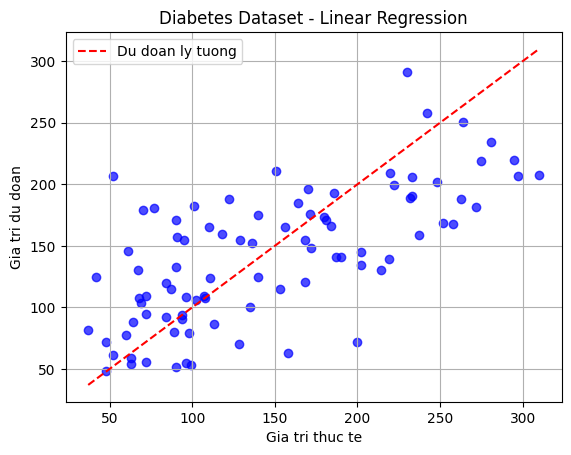

In [5]:
# BAI 3: LINEAR REGRESSION VOI DU LIEU DIABETES



import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


data = load_diabetes()

X = data.data
y = data.target

print("So mau du lieu:", X.shape[0])
print("So bien dau vao:", X.shape[1])
print("Ten cac bien:", data.feature_names)


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nSo mau train:", len(X_train))
print("So mau test:", len(X_test))


model = LinearRegression()


model.fit(X_train, y_train)


y_pred = model.predict(X_test)


mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nKET QUA DANH GIA")
print("MSE:", round(mse, 2))
print("R2:", round(r2, 4))


print("\nSO SANH THUC TE VA DU DOAN")

for i in range(min(10, len(y_test))):
    print(
        f"Thuc te: {y_test[i]:.2f} | "
        f"Du doan: {y_pred[i]:.2f}"
    )


plt.scatter(y_test, y_pred, alpha=0.7, color="blue")


min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Du doan ly tuong"
)

plt.xlabel("Gia tri thuc te")
plt.ylabel("Gia tri du doan")
plt.title("Diabetes Dataset - Linear Regression")
plt.legend()
plt.grid(True)
plt.show()